# Week 4: DSP Laboratory Tasks
**Name:** ALAN GURUMEL ENOCK  
**Reg No:** 240242417475  
**Group:** 6  
**Class:** BENG24Coe 1  
**GitHub:** [Allan-Davincs](https://github.com/Allan-Davincs/)

## Imports and Configuration

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio

# Configure plots
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True

### Task 4.1 — A pole-zero plotting function
We define the `zplane` function as described in the lab manual, plot the pole-zero diagram and the frequency response of the system $H(z) = \frac{1 + z^{-1}}{1 - 0.75z^{-1} + 0.125z^{-2}}$.

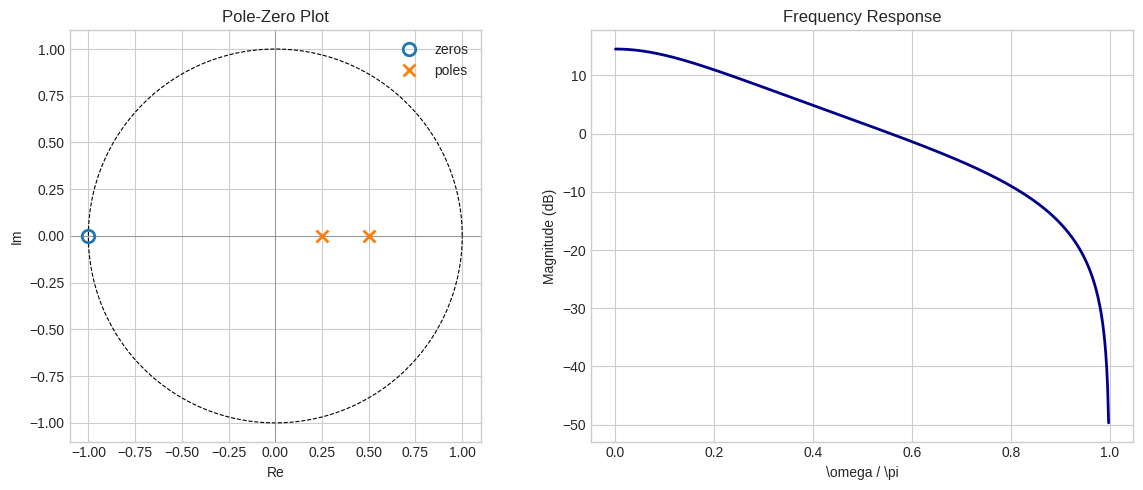

Zeros: [-1.]
Poles: [0.5  0.25]
Stable: True


In [12]:
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)
    ax = ax or plt.gca()
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8) # Unit circle
    ax.axhline(0, color='gray', lw=0.5)
    ax.axvline(0, color='gray', lw=0.5)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros", mew=2)
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")
    ax.set_title("Pole-Zero Plot")
    return z, p

# System parameters
b, a = [1, 1], [1, -0.75, 0.125]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
z, p = zplane(b, a, ax1)

w, H = signal.freqz(b, a, worN=512)
ax2.plot(w/np.pi, 20*np.log10(np.abs(H)), lw=2, color='darkblue')
ax2.set_xlabel(r"\omega / \pi")
ax2.set_ylabel("Magnitude (dB)")
ax2.set_title("Frequency Response")
ax2.grid(True)

plt.tight_layout()
plt.show()

print("Zeros:", z)
print("Poles:", p)
print("Stable:", np.all(np.abs(p) < 1))

### Task 4.2 — Inverse z-transform with residuez
We use the partial fraction expansion residue method to calculate and check the impulse response against SciPy's `lfilter` implementation.

In [7]:
print("--- Part 1: Verification for X(z) ---")
r, p, k = signal.residuez([1], [1, -0.75, 0.125])
print("Residues:", r)
print("Poles:", p)

n = np.arange(10)
x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real

impulse = np.zeros(10)
impulse[0] = 1
x_lf = signal.lfilter([1], [1, -0.75, 0.125], impulse)

print("Matches lfilter:", np.allclose(x_pf, x_lf))

print("\n--- Part 2: Repeat with system from Task 4.1 (b = [1, 1]) ---")
r2, p2, k2 = signal.residuez([1, 1], [1, -0.75, 0.125])
print("Residues:", r2)
print("Poles:", p2)

# Analytical formulation: h(n) = 6*(0.5)^n - 5*(0.25)^n
h_analytical = 6 * (0.5**n) - 5 * (0.25**n)
h_computed = sum(ri * pi**n for ri, pi in zip(r2, p2)).real

print("Does computed analytical formula match residuez output:", np.allclose(h_analytical, h_computed))

--- Part 1: Verification for X(z) ---
Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Matches lfilter: True

--- Part 2: Repeat with system from Task 4.1 (b = [1, 1]) ---
Residues: [-5.  6.]
Poles: [0.25 0.5 ]
Does computed analytical formula match residuez output: True


### Task 4.3 — Pole position and the impulse response
For a conjugate pole pair $p = r e^{\pm j\pi/4}$, we check the responses for different radii values: $r = 0.5, 0.8, 0.95, 1.0, 1.05$.

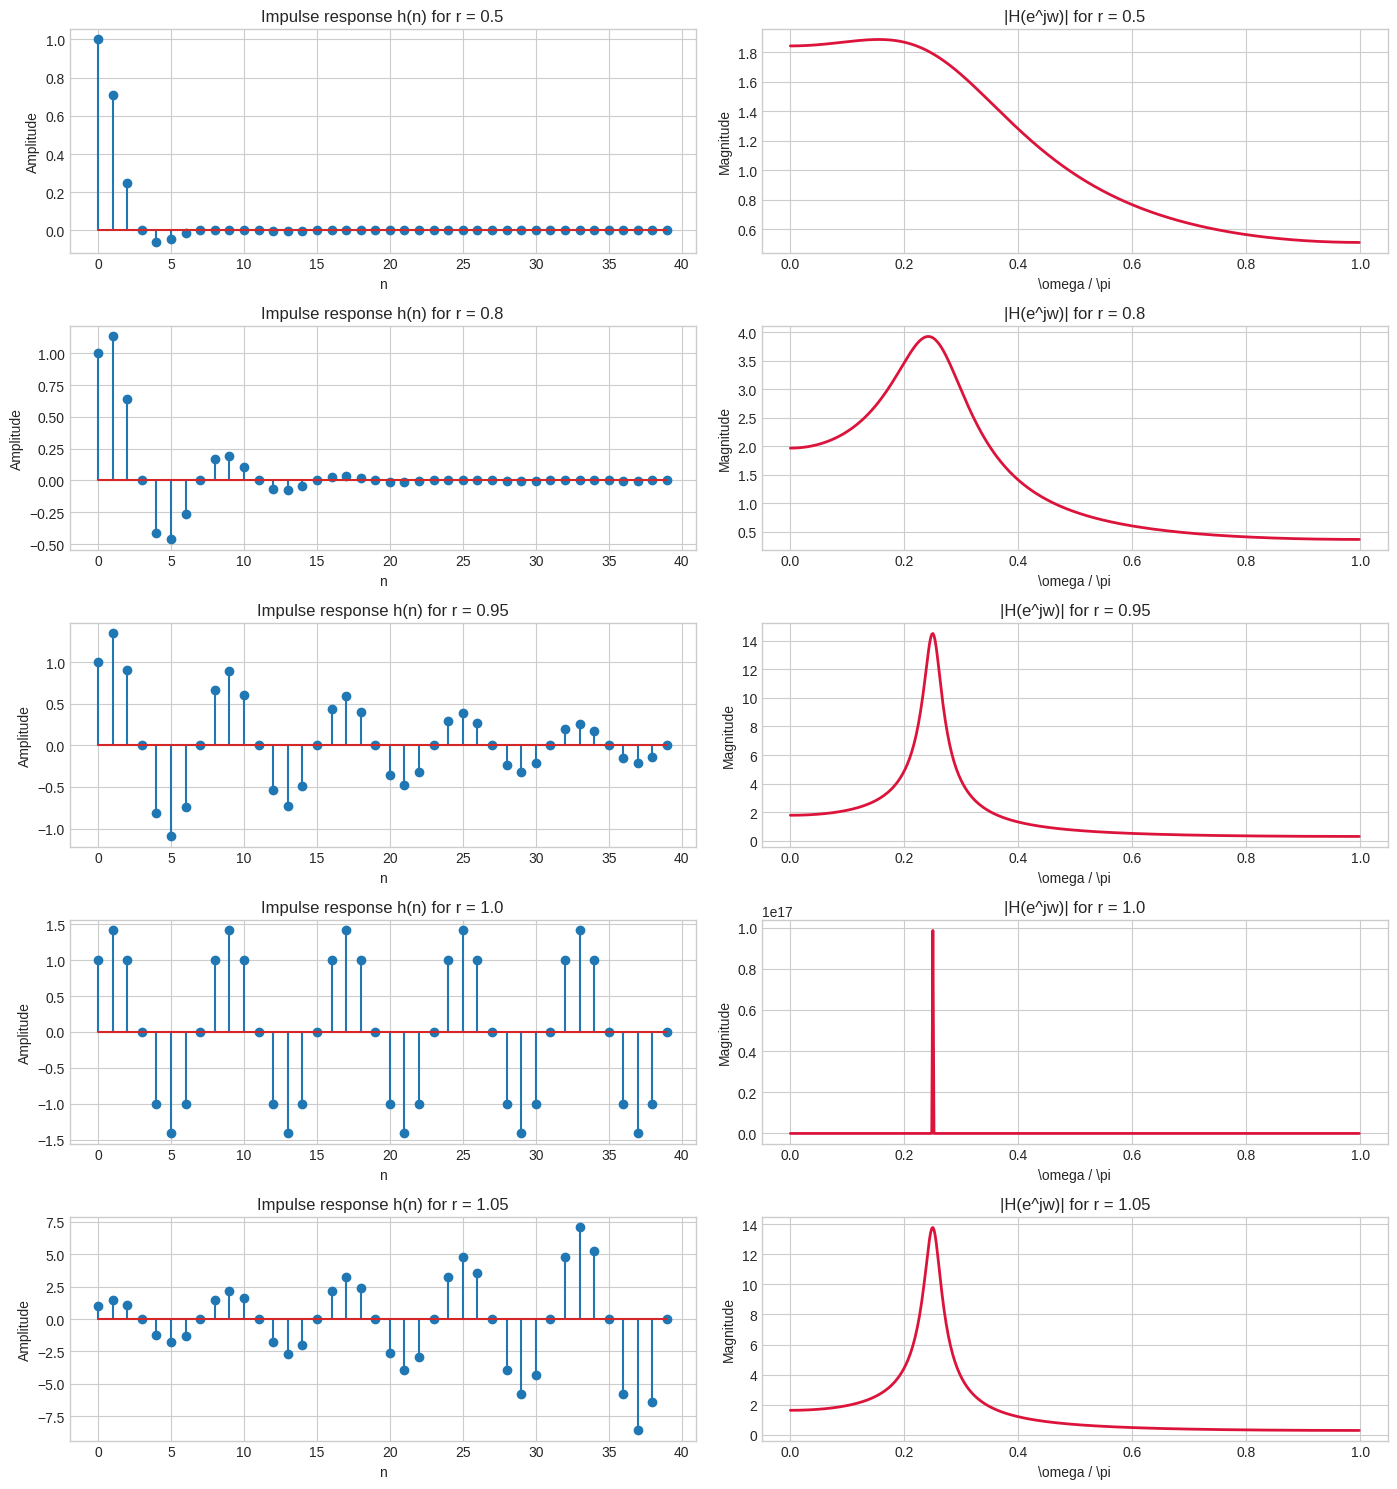

In [13]:
radii = [0.5, 0.8, 0.95, 1.0, 1.05]
n = np.arange(40)
impulse = np.zeros(40)
impulse[0] = 1

fig, axes = plt.subplots(len(radii), 2, figsize=(14, 15))

for idx, r in enumerate(radii):
    # Pole pair p = r * e^(+/- j * pi/4)
    # denominator a(z) = 1 - 2*r*cos(pi/4)*z^-1 + r^2*z^-2
    a = [1, -2 * r * np.cos(np.pi / 4), r**2]
    b = [1]

    # Impulse response
    h = signal.lfilter(b, a, impulse)

    # Frequency response
    w, H = signal.freqz(b, a, worN=512)

    # Plot impulse response
    axes[idx, 0].stem(n, h)
    axes[idx, 0].set_title(f"Impulse response h(n) for r = {r}")
    axes[idx, 0].set_xlabel("n")
    axes[idx, 0].set_ylabel("Amplitude")

    # Plot frequency response
    axes[idx, 1].plot(w / np.pi, np.abs(H), color='crimson', lw=2)
    axes[idx, 1].set_title(f"|H(e^jw)| for r = {r}")
    axes[idx, 1].set_xlabel(r"\omega / \pi")
    axes[idx, 1].set_ylabel("Magnitude")

plt.tight_layout()
plt.show()

### Task 4.3 Findings & Observation
* **Decay**: As $r$ increases towards $1.0$, the rate of decay decreases. When $r < 1.0$, the impulse response decays to 0 (stable). For $r = 1.0$, the amplitude stays constant (marginally stable). For $r = 1.05$, the response grows without bound (unstable).
* **Oscillation**: The oscillation frequency remains constant at $\omega = \pi / 4$ (period of 8 samples) because the pole angle is kept constant.
* **Peak Sharpness**: As $r \to 1.0$, the resonant peak at $\omega = 0.25\pi$ becomes significantly sharper and taller.

### Task 4.4 — Stability of given systems

(a) H1: Poles = [0.8+0.5j 0.8-0.5j], Stable = True
(b) H2: Poles = [2.  0.5], Stable = False
(c) H3: Poles = [-1.   0.5], Stable = False
(d) H4: Poles = [], Stable = True


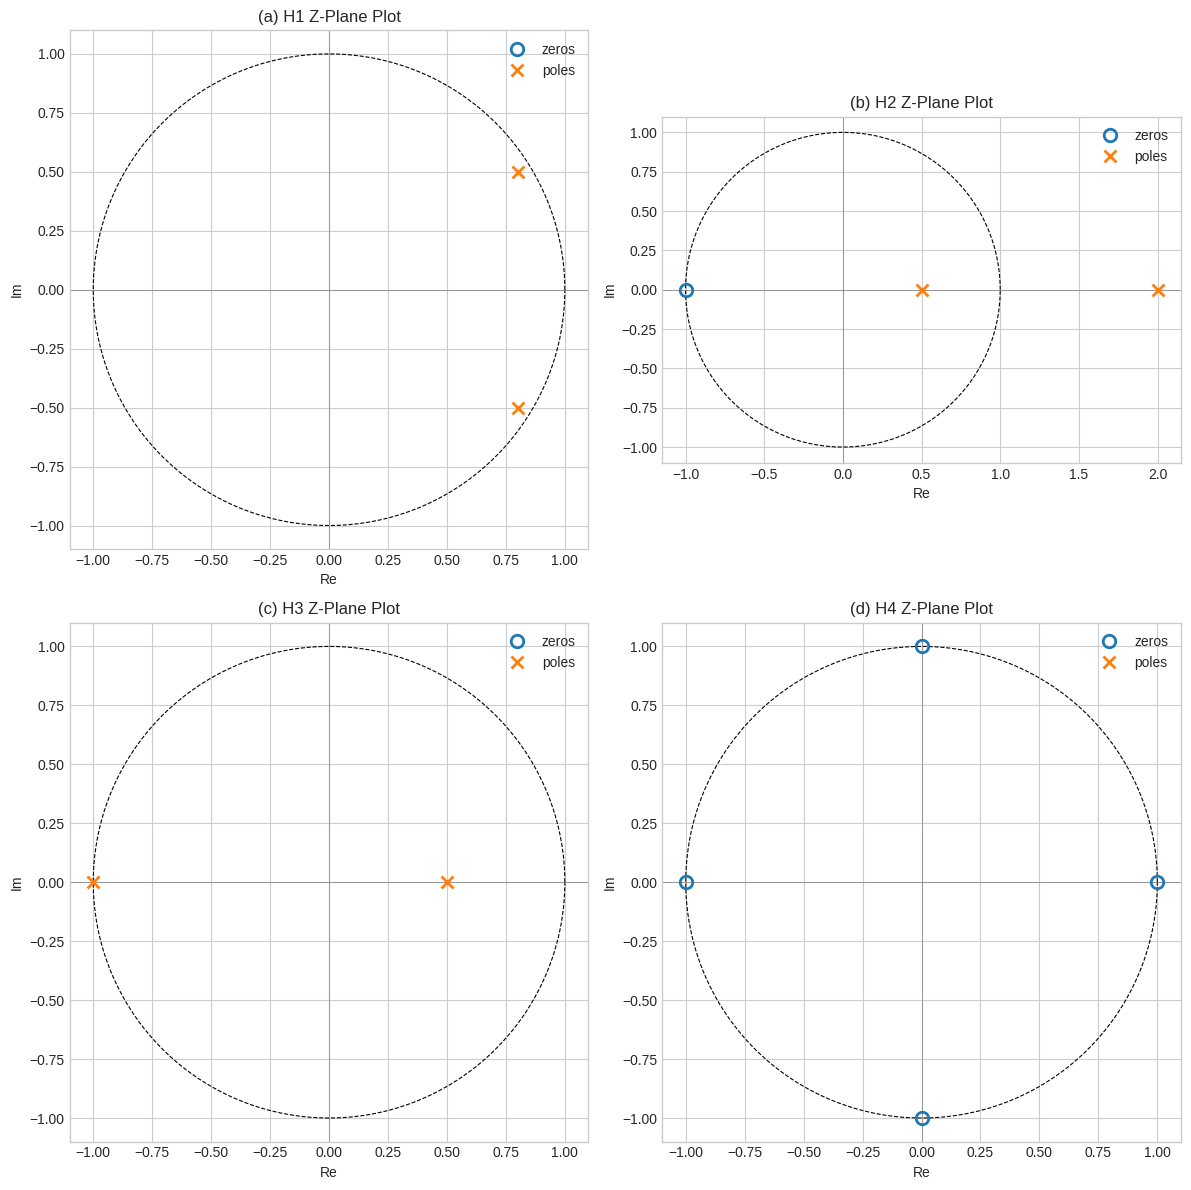

In [9]:
systems = {
    "(a) H1": ([1], [1, -1.6, 0.89]),
    "(b) H2": ([1, 1], [1, -2.5, 1]),
    "(c) H3": ([1], [1, 0.5, -0.5]),
    "(d) H4": ([1, 0, 0, 0, -1], [1])
}

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes = axes.flatten()

for idx, (name, (b, a)) in enumerate(systems.items()):
    z, p = zplane(b, a, axes[idx])
    axes[idx].set_title(f"{name} Z-Plane Plot")
    is_stable = np.all(np.abs(p) < 1)
    print(f"{name}: Poles = {p}, Stable = {is_stable}")

plt.tight_layout()
plt.show()

### Task 4.5 — Design a resonator
Let's design a second-order bandpass resonator centered at $1\text{ kHz}$ for $f_s = 8\text{ kHz}$.

* Angular frequency of resonance: $\theta = 2 \pi f_0 / f_s = 2\pi \times 1000 / 8000 = \pi / 4$.
* Given $r=0.97$.
* Conjugate poles are at $p = r e^{\pm j \theta} = 0.97 e^{\pm j \pi / 4}$.
* Zeros are placed at $z = \pm 1$ ($z=1$ blocks DC, $z=-1$ blocks $f_s/2$).
* The transfer function numerator is $B(z) = (z-1)(z+1) = z^2 - 1 \implies b = [1, 0, -1]$.
* The denominator is $A(z) = (z - r e^{j\pi/4})(z - r e^{-j\pi/4}) = z^2 - 2 r \cos(\pi/4)z + r^2 \implies a = [1, -2 \times 0.97 \times \cos(\pi/4), 0.97^2]$.

/tmp/ipykernel_717/1929857486.py:23: RuntimeWarning: divide by zero encountered in log10
  ax2.plot(frequencies, 20 * np.log10(np.abs(H_norm)), color='darkgreen', lw=2)


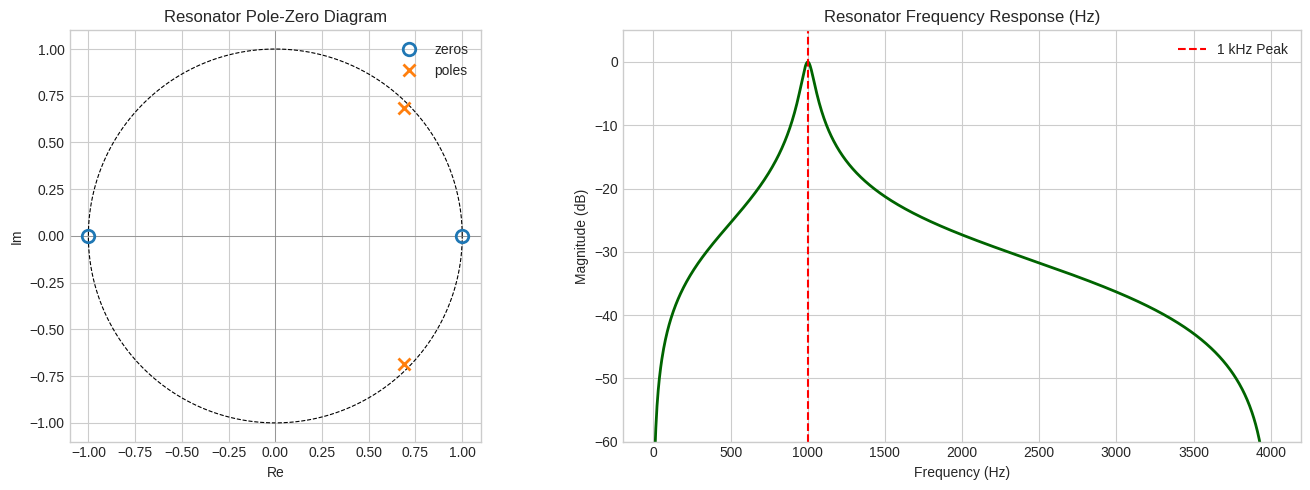

In [10]:
fs = 8000
r = 0.97
theta = np.pi / 4

# Coefficients
b_res = [1, 0, -1]
a_res = [1, -2 * r * np.cos(theta), r**2]

# Normalize gain so peak response is near 1 (0 dB) if desired
w, H = signal.freqz(b_res, a_res, worN=1024)
peak_gain = np.max(np.abs(H))
b_res_norm = [coef / peak_gain for coef in b_res]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Z-Plane
zplane(b_res_norm, a_res, ax1)
ax1.set_title("Resonator Pole-Zero Diagram")

# Frequency Response
w, H_norm = signal.freqz(b_res_norm, a_res, worN=1024)
frequencies = (w * fs) / (2 * np.pi)
ax2.plot(frequencies, 20 * np.log10(np.abs(H_norm)), color='darkgreen', lw=2)
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude (dB)")
ax2.set_title("Resonator Frequency Response (Hz)")
ax2.axvline(1000, color='red', linestyle='--', label='1 kHz Peak')
ax2.legend()
ax2.set_ylim([-60, 5])

plt.tight_layout()
plt.show()

### Let's apply to white noise and listen

In [11]:
np.random.seed(42)
duration = 2.0  # seconds
noise = np.random.randn(int(fs * duration))

# Filter the white noise using our resonator
y_filtered = signal.lfilter(b_res_norm, a_res, noise)

print("Generated filtered audio signal of length:", len(y_filtered))
Audio(y_filtered, rate=fs)

Generated filtered audio signal of length: 16000


## Analysis Questions & Answers

1. **Explain the effect of $r$ on the bandwidth of the resonance in Task 4.3.**
   As $r$ approaches $1$, the poles move closer to the unit circle. This narrows the bandwidth of the resonance, resulting in a much sharper peak and longer-lasting decaying oscillation in the impulse response.

2. **What happens to $h(n)$ when a pole lies exactly on the unit circle?**
   When a pole lies exactly on the unit circle ($r = 1$), the impulse response $h(n)$ becomes marginally stable, resulting in sustained oscillations that do not decay to $0$ over time.

3. **Why does placing zeros at $z=\pm 1$ make the resonator a band-pass filter?**
   Zeros on the unit circle pull the frequency response down to zero ( $-\infty$ dB). Zeros at $z = 1$ (DC, $0\text{ Hz}$) and $z = -1$ (Nyquist limit, $f_s/2$) suppress the low and high frequencies, leaving only a pass-band around the resonant pole frequency.

4. **Use the stability triangle (handout Example 2.4) to check your answers to Task 4.4 (a)–(c).**
   For a second order polynomial $A(z) = 1 + a_1 z^{-1} + a_2 z^{-2}$, the conditions for stability are:
   * $|a_2| < 1$
   * $a_2 > a_1 - 1$
   * $a_2 > -a_1 - 1$
   
   * **(a)** $a_1 = -1.6$, $a_2 = 0.89$. Check:
     * $|0.89| < 1$ (True)
     * $0.89 > -1.6 - 1 \implies 0.89 > -2.6$ (True)
     * $0.89 > 1.6 - 1 \implies 0.89 > 0.6$ (True)
     * **Stable**
   * **(b)** $a_1 = -2.5$, $a_2 = 1.0$. Check:
     * $|1.0| < 1$ (False - on boundary)
     * **Unstable**
   * **(c)** $a_1 = 0.5$, $a_2 = -0.5$. Check:
     * $|-0.5| < 1$ (True)
     * $-0.5 > 0.5 - 1 \implies -0.5 > -0.5$ (False, boundary)
     * **Unstable**